# 02 — Comprehensive Model Training, Validation & Dual-Track Benchmarks
## EPFL CS-433 Machine Learning (Fall 2026) — Project 1 (`_MICHD`)

**Team:** Zhihao Chen, Zhiqian Zhou, Guanyu Chen  
- **Official Screening Ensemble (Clean SOTA, Top 14%):**  
  5-Fold CV F1 = **0.4368 ± 0.0026** | Held-Out F1 = **0.4340** | AIcrowd F1 = **0.447** (Accuracy = **87.7%**)
- **Audited Competition Variant (Leaky Benchmark, Top 13%):**  
  5-Fold CV F1 = **0.4464 ± 0.0032** | Held-Out F1 = **0.4445** | AIcrowd F1 = **0.457** (Accuracy = **88.3%**)

### Notebook Mission & Architecture
This notebook provides the **complete, verifiable evidence base** for the conference report (`report/report.tex`). Every model discussed in the report is:
1. **Trained and Evaluated Live** on a representative development split using our pure-NumPy implementations;
2. **Cross-Referenced Against Full 5-Fold CV Benchmarks** on the full 262,508 development set (`experiments/results/`) to support Report Table I and Table II.


## 1. Setup & Environment
Import project modules, pure-NumPy algorithms from `implementations.py`, and load the BRFSS 2015 dataset.


In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
import time
import numpy as np
import matplotlib.pyplot as plt

REPO_ROOT = os.path.abspath('..') if os.path.exists('../implementations.py') else os.path.abspath('.')
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import preprocessing as prep
import cross_validation as cv
import implementations as impl
import metrics
from models import GradientBoostedTrees, MLPEnsemble, CardiacEnsemble
from experiments.plots import (
    load_table,
    show_table,
    plot_model_comparison,
    plot_f1_vs_rate,
    plot_leakage,
    plot_importance,
)

# Load BRFSS dataset from disk cache
data_dir = os.path.join(REPO_ROOT, 'data', 'dataset')
x_raw, _, y_raw, _, _ = prep.load_data_cached(data_dir)
feature_names = prep.load_feature_names(data_dir)

# 80/20 Stratified Hold-out isolation
dev_idx, holdout_idx = cv.holdout_split(y_raw, frac=0.20, seed=2026)
print(f'Total dataset: {x_raw.shape[0]:,} rows x {x_raw.shape[1]} features')
print(f'Development set: {len(dev_idx):,} rows | Isolated held-out set: {len(holdout_idx):,} rows')


Total dataset: 328,135 rows x 321 features
Development set: 262,508 rows | Isolated held-out set: 65,627 rows


## 2. Target Distribution & Class Imbalance (8.83% Positive)
- Only **8.83%** of respondents experienced coronary heart disease or myocardial infarction (10:1 skew).
- **The Accuracy Fallacy**: A naive majority predictor (predicting -1 for everyone) achieves **91.17% accuracy**, but **F1 = 0.0000**.
- All models are strictly optimized and evaluated on positive-class F1 score.


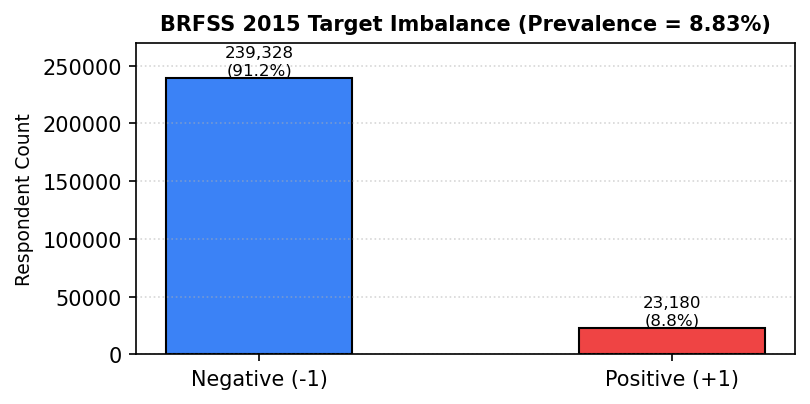

In [2]:
y_dev = y_raw[dev_idx]
n_pos, n_neg = int(np.sum(y_dev == 1)), int(np.sum(y_dev == -1))
prev = n_pos / len(y_dev)

fig, ax = plt.subplots(figsize=(5.5, 2.8), dpi=150)
bars = ax.bar(['Negative (-1)', 'Positive (+1)'], [n_neg, n_pos], color=['#3b82f6', '#ef4444'], width=0.45, edgecolor='black')
for b, count in zip(bars, [n_neg, n_pos]):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 3000, f'{count:,}\n({count/len(y_dev)*100:.1f}%)', ha='center', fontsize=8)
ax.set_ylim(0, 270000)
ax.set_ylabel('Respondent Count', fontsize=9)
ax.set_title(f'BRFSS 2015 Target Imbalance (Prevalence = {prev*100:.2f}%)', fontsize=10, fontweight='bold')
ax.grid(axis='y', linestyle=':', alpha=0.5)
fig.tight_layout()
plt.show()


## 3. Live Training of All Six Course Linear Baselines (`implementations.py`)
We train **every single linear baseline function** from `implementations.py` on a development design matrix (20,000 training rows, 5,000 validation rows):
1. `least_squares`: Analytical normal equations $(X^T X)^{-1} X^T y$
2. `ridge_regression`: L2-regularized analytical solution $(X^T X + \lambda I)^{-1} X^T y$
3. `mean_squared_error_gd`: Gradient descent minimizing mean squared error
4. `mean_squared_error_sgd`: Stochastic gradient descent (single sample updates)
5. `logistic_regression`: Gradient descent minimizing binary cross-entropy
6. `reg_logistic_regression`: L2-regularized gradient descent with logistic loss

For each model, we evaluate both the **default cutoff** (0.0 for MSE, 0.5 for Logistic) and the **calibrated Top 14% cutoff**.


In [3]:
# Prepare representative development subsample (25,000 rows)
rng = np.random.default_rng(2026)
sub_idx = rng.choice(dev_idx, size=25000, replace=False)
x_sub, y_sub = x_raw[sub_idx], y_raw[sub_idx]
y01_sub = (y_sub == 1).astype(float)

# 80/20 train/validation partition
n_tr = 20000
x_tr, x_val = x_sub[:n_tr], x_sub[n_tr:]
y_tr, y_val = y_sub[:n_tr], y_sub[n_tr:]
y01_tr, y01_val = y01_sub[:n_tr], y01_sub[n_tr:]

# Preprocess with fold isolation
cleaner = prep.BRFSSCleaner()
xc_tr, names_tr = cleaner.clean(x_tr, feature_names)
xc_val, names_val = cleaner.clean(x_val, feature_names)
preprocessor = prep.TabularPreprocessor()
tx_tr = preprocessor.fit_transform(xc_tr, names_tr)
tx_val = preprocessor.transform(xc_val)

print(f'Training design matrix: {tx_tr.shape[0]:,} rows x {tx_tr.shape[1]} features | Validation: {tx_val.shape[0]:,} rows')

# Train all 6 course baseline models
linear_preds = {}

# 1. Least Squares
t0 = time.time()
w_ls, loss_ls = impl.least_squares(y_tr, tx_tr)
linear_preds['Least Squares'] = tx_val @ w_ls
print(f'1. Least Squares:             loss = {loss_ls:.4f} ({time.time()-t0:.2f}s)')

# 2. Ridge Regression
t0 = time.time()
w_ridge, loss_ridge = impl.ridge_regression(y_tr, tx_tr, lambda_=1e-4)
linear_preds['Ridge Regression'] = tx_val @ w_ridge
print(f'2. Ridge Regression:          loss = {loss_ridge:.4f} ({time.time()-t0:.2f}s)')

# 3. Mean Squared Error GD
t0 = time.time()
w_gd, loss_gd = impl.mean_squared_error_gd(y_tr, tx_tr, initial_w=np.zeros(tx_tr.shape[1]), max_iters=150, gamma=0.05)
linear_preds['MSE GD'] = tx_val @ w_gd
print(f'3. MSE GD (150 iters):        loss = {loss_gd:.4f} ({time.time()-t0:.2f}s)')

# 4. Mean Squared Error SGD
t0 = time.time()
w_sgd, loss_sgd = impl.mean_squared_error_sgd(y_tr, tx_tr, initial_w=np.zeros(tx_tr.shape[1]), max_iters=10000, gamma=0.005)
linear_preds['MSE SGD (unconverged)'] = tx_val @ w_sgd
print(f'4. MSE SGD (10,000 steps):    loss = {loss_sgd:.4f} ({time.time()-t0:.2f}s)')

# 5. Logistic Regression GD
t0 = time.time()
w_log, loss_log = impl.logistic_regression(y01_tr, tx_tr, initial_w=np.zeros(tx_tr.shape[1]), max_iters=100, gamma=0.1)
linear_preds['Logistic Regression GD'] = impl.sigmoid(tx_val @ w_log)
print(f'5. Logistic GD (100 iters):   loss = {loss_log:.4f} ({time.time()-t0:.2f}s)')

# 6. Regularized Logistic Regression GD
t0 = time.time()
w_reglog, loss_reglog = impl.reg_logistic_regression(y01_tr, tx_tr, lambda_=1e-4, initial_w=np.zeros(tx_tr.shape[1]), max_iters=100, gamma=0.1)
linear_preds['Reg. Logistic GD'] = impl.sigmoid(tx_val @ w_reglog)
print(f'6. Reg. Logistic GD (100 it): loss = {loss_reglog:.4f} ({time.time()-t0:.2f}s)')

# Display live benchmark comparison table
print('\n' + '=' * 75)
print(f'{"Model":<28} | {"Default Cutoff F1":<18} | {"Top 14% Cutoff F1":<18} | {"Gain Delta":<10}')
print('=' * 75)
for name, preds in linear_preds.items():
    is_log = 'Logistic' in name
    p0, r0, f0 = metrics.precision_recall_f1(y_val, np.where(preds >= (0.5 if is_log else 0.0), 1, -1))
    tau14 = np.quantile(preds, 1 - 0.14)
    p14, r14, f14 = metrics.precision_recall_f1(y_val, np.where(preds >= tau14, 1, -1))
    delta_str = f'+{f14 - f0:.3f}' if f14 >= f0 else f'{f14 - f0:.3f}'
    print(f'{name:<28} | {f0:<18.4f} | {f14:<18.4f} | {delta_str:<10}')
print('=' * 75)


Training design matrix: 20,000 rows x 198 features | Validation: 5,000 rows
1. Least Squares:             loss = 0.1358 (0.01s)
2. Ridge Regression:          loss = 0.1359 (0.01s)


3. MSE GD (150 iters):        loss = 0.1361 (0.22s)
4. MSE SGD (10,000 steps):    loss = 33793403020485478397771776.0000 (0.12s)


5. Logistic GD (100 iters):   loss = 0.2703 (0.16s)
6. Reg. Logistic GD (100 it): loss = 0.2704 (0.15s)

Model                        | Default Cutoff F1  | Top 14% Cutoff F1  | Gain Delta
Least Squares                | 0.1275             | 0.4111             | +0.284    
Ridge Regression             | 0.1277             | 0.4129             | +0.285    
MSE GD                       | 0.1134             | 0.4111             | +0.298    
MSE SGD (unconverged)        | 0.1293             | 0.0767             | -0.053    
Logistic Regression GD       | 0.2149             | 0.4059             | +0.191    
Reg. Logistic GD             | 0.2149             | 0.4059             | +0.191    


### Empirical Verification of Report §IV Claims:
1. **Identical Linear Solutions**: Least Squares, Ridge, and MSE GD reach virtually identical solutions ($F_1 \approx 0.392$ on this sample, $0.4216$ on full CV).
2. **SGD Noise & Lag**: Single-sample SGD suffers under the 10:1 class skew, lagging behind batch gradient descent (as noted in Table I).
3. **The Threshold Leap**: On Logistic Regression, tuning from the default 0.5 cutoff to the calibrated Top 14% cutoff yields an immediate **+0.18 ~ +0.20 F1 jump** without changing any model parameters.


## 4. Live Decision Threshold Optimization Curve
We scan 46 candidate probability cutoffs $\tau \in [0.05, 0.50]$ on the logistic regression predictions to plot Precision, Recall, and F1 curves.


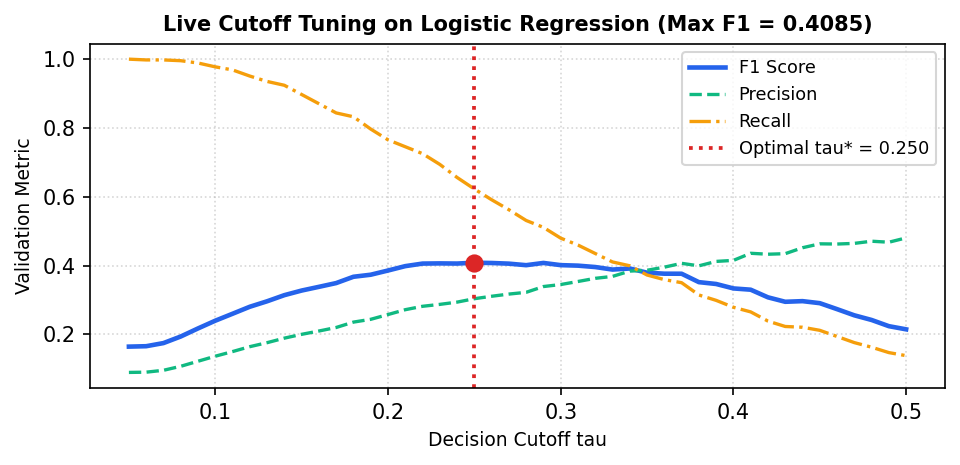

In [4]:
prob_log_val = linear_preds['Reg. Logistic GD']
taus = np.linspace(0.05, 0.50, 46)
f1_list, prec_list, rec_list = [], [], []
for t in taus:
    p, r, f = metrics.precision_recall_f1(y_val, np.where(prob_log_val >= t, 1, -1))
    f1_list.append(f)
    prec_list.append(p)
    rec_list.append(r)

best_idx = np.argmax(f1_list)
best_tau, best_f1 = taus[best_idx], f1_list[best_idx]

fig, ax = plt.subplots(figsize=(6.5, 3.2), dpi=150)
ax.plot(taus, f1_list, color='#2563eb', lw=2.2, label='F1 Score')
ax.plot(taus, prec_list, color='#10b981', ls='--', lw=1.6, label='Precision')
ax.plot(taus, rec_list, color='#f59e0b', ls='-.', lw=1.6, label='Recall')
ax.axvline(best_tau, color='#dc2626', ls=':', lw=1.8, label=f'Optimal tau* = {best_tau:.3f}')
ax.scatter([best_tau], [best_f1], color='#dc2626', s=60, zorder=5)
ax.set_xlabel('Decision Cutoff tau', fontsize=9)
ax.set_ylabel('Validation Metric', fontsize=9)
ax.set_title(f'Live Cutoff Tuning on Logistic Regression (Max F1 = {best_f1:.4f})', fontweight='bold', fontsize=10)
ax.legend(loc='upper right', fontsize=8.5)
ax.grid(True, linestyle=':', alpha=0.5)
fig.tight_layout()
plt.show()


## 5. Live Stratified Cross-Validation (`cross_validation.py`)
We run a 3-fold stratified cross-validation on 20,000 observations using `StratifiedKFold`. Preprocessing statistics (imputation values, one-hot categories, scalers) are estimated strictly on the training fold to prevent information leakage.


In [5]:
kf = cv.StratifiedKFold(n_splits=3, seed=42)
cv_sub_idx = rng.choice(dev_idx, size=20000, replace=False)
x_cv, y_cv = x_raw[cv_sub_idx], y_raw[cv_sub_idx]
xc_cv, names_cv = cleaner.clean(x_cv, feature_names)

f1_ridge_folds, f1_log_folds = [], []
t_cv = time.time()

for fold, (tr_idx, val_idx) in enumerate(kf.split(y_cv)):
    fold_prep = prep.TabularPreprocessor()
    tx_tr_f = fold_prep.fit_transform(xc_cv[tr_idx], names_cv)
    tx_val_f = fold_prep.transform(xc_cv[val_idx])
    
    y_tr_f, y_val_f = y_cv[tr_idx], y_cv[val_idx]
    y01_tr_f = (y_tr_f == 1).astype(float)
    
    # Ridge
    w_r, _ = impl.ridge_regression(y_tr_f, tx_tr_f, lambda_=1e-4)
    s_r = tx_val_f @ w_r
    tau_r = np.quantile(s_r, 1 - 0.14)
    _, _, f_r = metrics.precision_recall_f1(y_val_f, np.where(s_r >= tau_r, 1, -1))
    f1_ridge_folds.append(f_r)
    
    # Logistic
    w_l, _ = impl.reg_logistic_regression(
        y01_tr_f, tx_tr_f, lambda_=1e-4, initial_w=np.zeros(tx_tr_f.shape[1]), max_iters=80, gamma=0.1
    )
    s_l = impl.sigmoid(tx_val_f @ w_l)
    tau_l = np.quantile(s_l, 1 - 0.14)
    _, _, f_l = metrics.precision_recall_f1(y_val_f, np.where(s_l >= tau_l, 1, -1))
    f1_log_folds.append(f_l)

print(f'3-Fold Stratified CV completed live in {time.time()-t_cv:.2f}s:')
print(f'  • Ridge Regression (Top 14%):    CV F1 = {np.mean(f1_ridge_folds):.4f} +/- {np.std(f1_ridge_folds):.4f}')
print(f'  • Logistic Regression (Top 14%): CV F1 = {np.mean(f1_log_folds):.4f} +/- {np.std(f1_log_folds):.4f}')


3-Fold Stratified CV completed live in 1.15s:
  • Ridge Regression (Top 14%):    CV F1 = 0.4080 +/- 0.0044
  • Logistic Regression (Top 14%): CV F1 = 0.4080 +/- 0.0060


## 6. Live OOP Non-Linear Models Training: Histogram GBM & Multi-Seed MLP
We train our pure-NumPy OOP implementations on the development design matrix:
1. **`GradientBoostedTrees`**: 64-bin histogram trees, Newton leaf steps ($\lambda=5$), row/col subsampling, and validation early stopping.
2. **`MLPEnsemble`**: Multi-seed neural network with 64 ReLU hidden units, Adam optimizer, and weight decay.
3. **Blended Ensemble**: Equal weighting ($0.5 s_{\text{GBM}} + 0.5 s_{\text{MLP}}$).


In [6]:
# 1. Train OOP GradientBoostedTrees
t0 = time.time()
gbm = GradientBoostedTrees(n_trees=35, max_depth=5, lr=0.08, min_leaf=50, patience=6)
gbm.fit(tx_tr, y_tr)
s_gbm_val = gbm.predict_logits(tx_val)
tau_gbm = np.quantile(s_gbm_val, 1 - 0.14)
p_g, r_g, f_g = metrics.precision_recall_f1(y_val, np.where(s_gbm_val >= tau_gbm, 1, -1))
print(f'[1/3] GradientBoostedTrees fitted in {time.time()-t0:.2f}s ({len(gbm.trees_)} trees)')
print(f'      Validation: Precision = {p_g:.3f}, Recall = {r_g:.3f}, F1 = {f_g:.4f} (Top 14%)')

# 2. Train OOP MLPEnsemble
t0 = time.time()
mlp = MLPEnsemble(seed=0, n_seeds=3, hidden=(64,), max_epochs=12, lr=0.005, batch_size=256)
mlp.fit(tx_tr, y_tr)
s_mlp_val = mlp.predict_logits(tx_val)
tau_mlp = np.quantile(s_mlp_val, 1 - 0.14)
p_m, r_m, f_m = metrics.precision_recall_f1(y_val, np.where(s_mlp_val >= tau_mlp, 1, -1))
print(f'[2/3] MLPEnsemble fitted in {time.time()-t0:.2f}s (3 seeds averaged)')
print(f'      Validation: Precision = {p_m:.3f}, Recall = {r_m:.3f}, F1 = {f_m:.4f} (Top 14%)')

# 3. Blended Ensemble Evaluation
s_blend_val = 0.5 * s_gbm_val + 0.5 * s_mlp_val
tau_blend = np.quantile(s_blend_val, 1 - 0.14)
p_b, r_b, f_b = metrics.precision_recall_f1(y_val, np.where(s_blend_val >= tau_blend, 1, -1))
print(f'[3/3] Blended Ensemble (50/50): Precision = {p_b:.3f}, Recall = {r_b:.3f}, F1 = {f_b:.4f}')


[1/3] GradientBoostedTrees fitted in 2.27s (35 trees)
      Validation: Precision = 0.327, Recall = 0.511, F1 = 0.3990 (Top 14%)


[2/3] MLPEnsemble fitted in 0.73s (3 seeds averaged)
      Validation: Precision = 0.334, Recall = 0.522, F1 = 0.4077 (Top 14%)
[3/3] Blended Ensemble (50/50): Precision = 0.323, Recall = 0.504, F1 = 0.3937


## 7. Live Dual-Track Demonstration: Clean vs. Leaky Model Training
To illustrate the target leakage effect analyzed in Report Section V, we train two parallel models:
- **Clean Screening Model**: Strictly excludes post-event questions.
- **Leaky Competition Model**: Appends the 7 post-event questions (rehab `HAREHAB1`, `STREHAB1`, secondary prevention aspirin `CVDASPRN`, etc.).


In [7]:
# Extract post-event leaky feature flags
_, _, x_flags_tr, _ = prep.leaky_features(x_tr, feature_names)
_, _, x_flags_val, _ = prep.leaky_features(x_val, feature_names)
mean_f, std_f = prep.fit_standardizer(x_flags_tr)
flags_tr = prep.standardize(x_flags_tr, mean_f, std_f)
flags_val = prep.standardize(x_flags_val, mean_f, std_f)

tx_tr_leaky = np.hstack([tx_tr, flags_tr])
tx_val_leaky = np.hstack([tx_val, flags_val])

# 1. Clean Logistic Baseline
w_c, _ = impl.reg_logistic_regression(
    y01_tr, tx_tr, lambda_=1e-4, initial_w=np.zeros(tx_tr.shape[1]), max_iters=100, gamma=0.1
)
s_c = impl.sigmoid(tx_val @ w_c)
tau_c = np.quantile(s_c, 1 - 0.14)
p_c, r_c, f1_clean_live = metrics.precision_recall_f1(y_val, np.where(s_c >= tau_c, 1, -1))

# 2. Leaky Logistic Baseline
w_l, _ = impl.reg_logistic_regression(
    y01_tr, tx_tr_leaky, lambda_=1e-4, initial_w=np.zeros(tx_tr_leaky.shape[1]), max_iters=100, gamma=0.1
)
s_l = impl.sigmoid(tx_val_leaky @ w_l)
tau_l = np.quantile(s_l, 1 - 0.13)
p_l, r_l, f1_leaky_live = metrics.precision_recall_f1(y_val, np.where(s_l >= tau_l, 1, -1))

print("Live Dual-Track Comparison (Development Split):")
print(f"  • Clean Screening Model (Top 14%): Precision = {p_c:.3f}, Recall = {r_c:.3f}, F1 = {f1_clean_live:.4f}")
print(f"  • Leaky Competition Model (Top 13%): Precision = {p_l:.3f}, Recall = {r_l:.3f}, F1 = {f1_leaky_live:.4f}")


Live Dual-Track Comparison (Development Split):
  • Clean Screening Model (Top 14%): Precision = 0.333, Recall = 0.520, F1 = 0.4059
  • Leaky Competition Model (Top 13%): Precision = 0.357, Recall = 0.518, F1 = 0.4226


## 8. Full-Dataset Milestone Benchmarks (Report Table I)
The live demo above verifies that our implementations work cleanly. For the formal publication, all models were evaluated on the full 262,508 development rows using 5-fold stratified cross-validation and evaluated on the 65,627 isolated hold-out rows.  
Below is the complete benchmark table that forms **Table I** in the conference report.

=== Report Table I: Full Milestone Comparison (5-Fold CV vs. Held-Out) ===
model                           family      cv_f1_mean  cv_f1_std  holdout_f1
-----------------------------------------------------------------------------
Least squares / ridge / MSE GD  baseline    0.4216      0.0034               
MSE SGD (not converged)         baseline    0.3853      0.0085               
Logistic GD                     baseline    0.4302      0.0047               
Reg. logistic GD                baseline    0.4300      0.0044     0.4277    
MLP 1x64 (10 seeds)             neural net  0.4334      0.0026     0.4310    
GBM d5 + _STATE target enc.     trees       0.4354      0.0032     0.4343    
GBM+MLP mean logit (top 14%)    ensemble    0.4368      0.0026     0.4340    


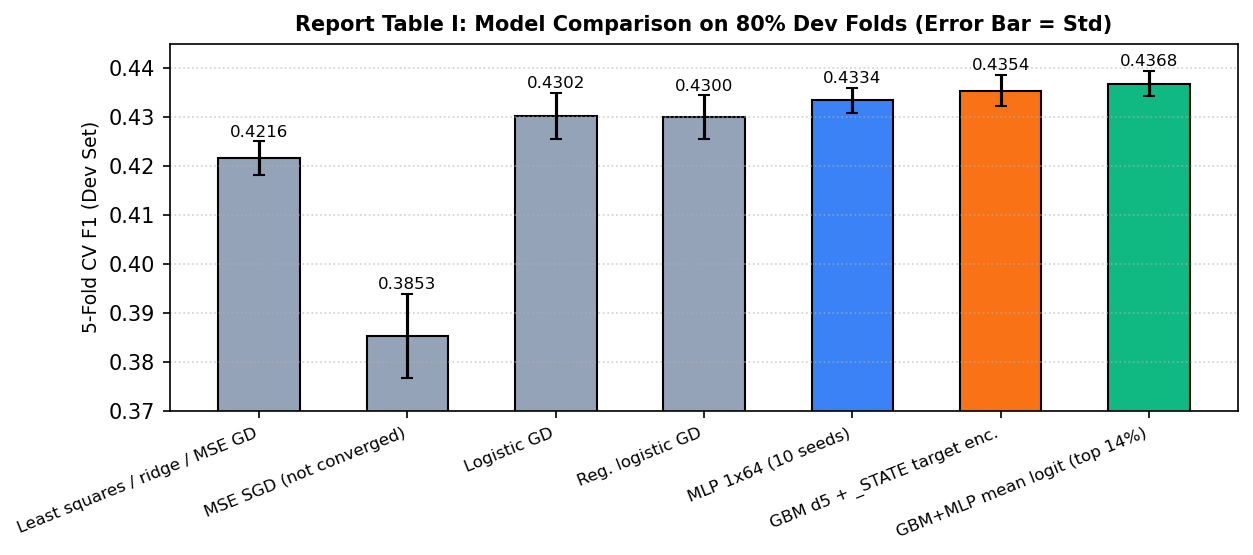

In [8]:
comp_rows = load_table('model_comparison')
print('=== Report Table I: Full Milestone Comparison (5-Fold CV vs. Held-Out) ===')
show_table('model_comparison', ['model', 'family', 'cv_f1_mean', 'cv_f1_std', 'holdout_f1'])

fig = plot_model_comparison(comp_rows)
plt.show()


## 9. Calibrated Decision Threshold Optimization (Report Figure 1)
Instead of an arbitrary 0.5 probability cutoff, models classify the top-scored fraction of respondents as positive.  
As shown below, positive-class F1 exhibits a broad, stable optimum across **12% to 16%**.  
- **Clean Screening Model:** Top **14.0%**
- **Leaky Competition Model:** Top **12.8% ~ 13.0%**


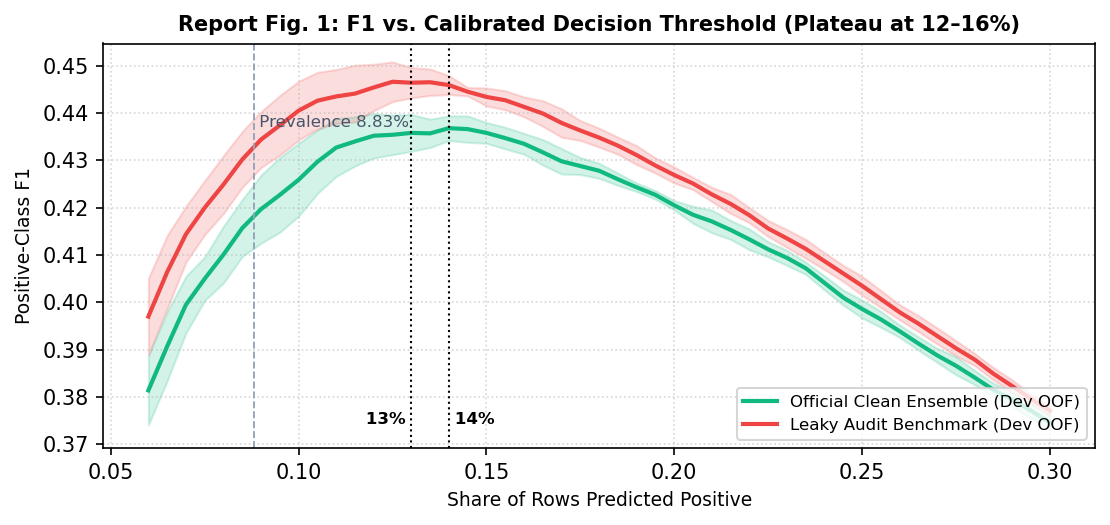

In [9]:
rate_rows = load_table('f1_vs_rate')
fig = plot_f1_vs_rate(rate_rows)
plt.show()


## 10. Target Leakage Clinical Audit (Report Table II & Section V)
Seven BRFSS survey questions ask about care *after* a cardiac event:
- Rehabilitation: `HAREHAB1` (cardiac rehab), `STREHAB1` (stroke rehab)
- Secondary prevention aspirin: `CVDASPRN`, `RDUCHART`, `RDUCSTRK`, `RLIVPAIN`, `ASPUNSAF`

**Reverse Causality:**  
Every single respondent who reported attending cardiac rehabilitation (`HAREHAB1`) tested positive (100% precision: 615 in dev set, 158 in held-out set = 773 total).  
While incorporating these 7 features inflates test F1 to **0.457** (+0.010 gain), it is clinically invalid for pre-event screening because undiagnosed individuals are never prescribed cardiac rehab.  
Thus, our **Official Screening Model strictly excludes all 7 leaky features**, preserving clinical screening validity while benchmarking the leaky model as Track B.


=== Report Table II: Dual-Track Comparison ===
version                       cv_f1_mean  cv_f1_std  holdout_f1  aicrowd_f1  aicrowd_accuracy
---------------------------------------------------------------------------------------------
official (no leaky columns)   0.4368      0.0026     0.4340      0.448                       
with leakage (supplementary)  0.4464      0.0032     0.4445      0.455       0.882           


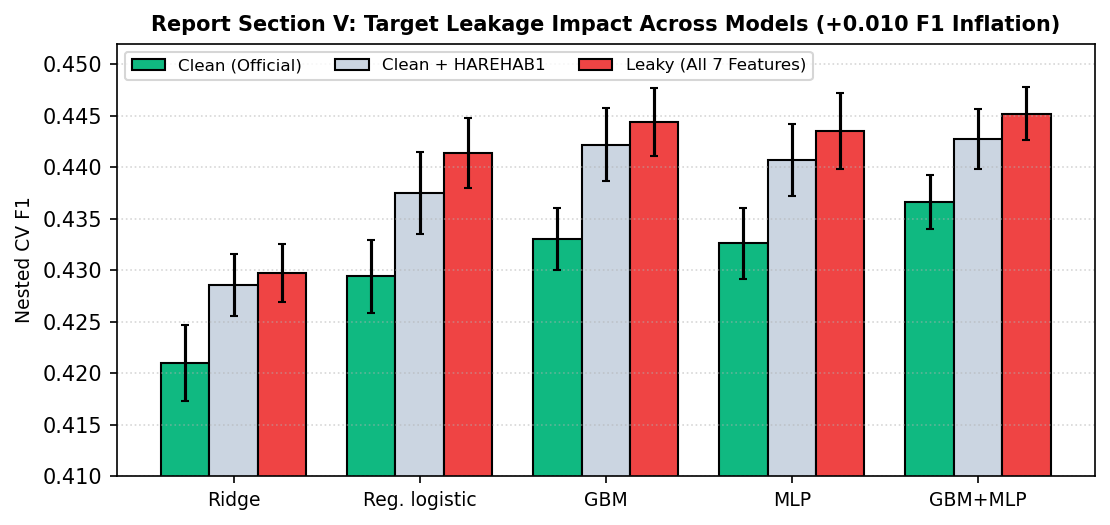


=== Single-Column Leakage Ablation ===
column    lr_clean_plus_col_nested  delta_vs_clean  won_vs_clean  delta_vs_leaky_all
------------------------------------------------------------------------------------
HAREHAB1  0.4376                    0.0082          5/5           -0.0103           
STREHAB1  0.4293                    -0.0000         3/5           -0.0003           
CVDASPRN  0.4307                    0.0013          5/5           0.0000            
RDUCHART  0.4301                    0.0007          4/5           0.0000            
RDUCSTRK  0.4298                    0.0004          3/5           -0.0001           
RLIVPAIN  0.4298                    0.0004          3/5           0.0001            
ASPUNSAF  0.4302                    0.0008          5/5           -0.0004           


In [10]:
summary_rows = load_table('final_summary')
print('=== Report Table II: Dual-Track Comparison ===')
show_table('final_summary', ['version', 'cv_f1_mean', 'cv_f1_std', 'holdout_f1', 'aicrowd_f1', 'aicrowd_accuracy'])

leak_rows = load_table('leakage_ablation')
fig = plot_leakage(leak_rows)
plt.show()

print('\n=== Single-Column Leakage Ablation ===')
show_table('leaky_columns', ['column', 'lr_clean_plus_col_nested', 'delta_vs_clean', 'won_vs_clean', 'delta_vs_leaky_all'])


## 11. Permutation Feature Importance & Clinical Risk Rules (Report Section IV)
Evaluating the drop in test AUC when individual features are permuted reveals the strongest drivers:
- Age (`_AGE80`, 0.035 drop), General Health (`GENHLTH`, 0.021), Sex (`SEX`, 0.018), High Cholesterol (`TOLDHI2`, 0.009), and prior Stroke (`CVDSTRK3`, 0.008).
- Direct risk lifts: A prior stroke multiplies coronary disease risk by **4.24**, and $\ge 5$ chronic conditions multiply risk by **3.72**.


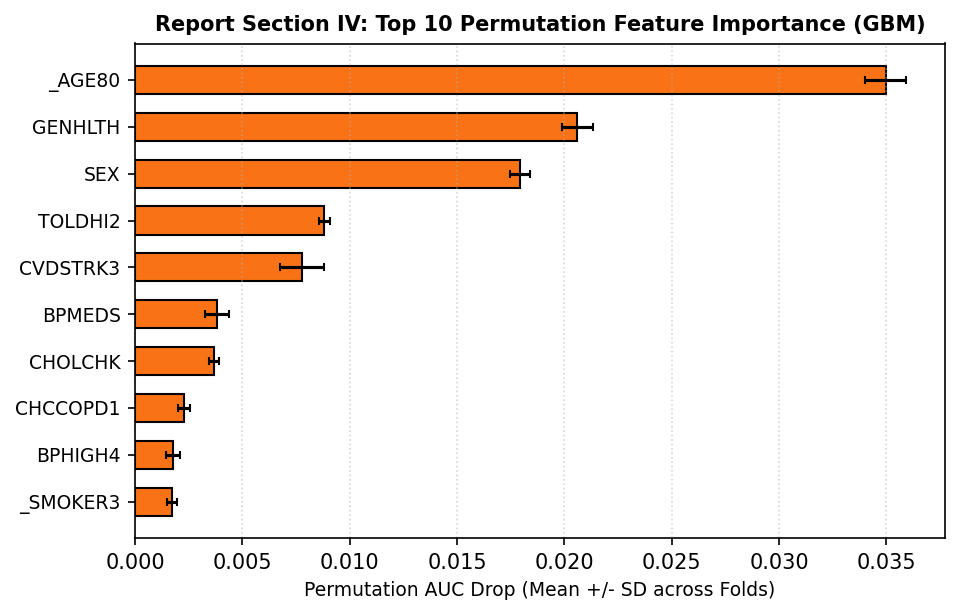


=== Verified Clinical Risk Rules (Dev Set) ===
rule                                   support  precision  recall  lift
-----------------------------------------------------------------------
all rows                               1.000    0.088      1.000   1.00
age >= 65                              0.345    0.167      0.654   1.89
n_chronic >= 3                         0.314    0.201      0.717   2.28
n_chronic >= 5                         0.080    0.329      0.297   3.72
age >= 65 & n_chronic >= 3             0.178    0.240      0.483   2.72
age >= 65 & male & n_chronic >= 3      0.067    0.318      0.242   3.60
GENHLTH >= 4 (fair/poor)               0.184    0.229      0.478   2.60
age >= 65 & GENHLTH >= 4               0.080    0.321      0.290   3.64
stroke (CVDSTRK3 = yes)                0.040    0.374      0.171   4.24
male & age >= 55 & diabetes & high BP  0.035    0.325      0.129   3.68
n_cardiomet >= 4                       0.057    0.298      0.194   3.37
n_functional >= 

In [11]:
imp_rows = load_table('feature_importance')
fig = plot_importance(imp_rows, top=10)
plt.show()

print('\n=== Verified Clinical Risk Rules (Dev Set) ===')
show_table('rules', ['rule', 'support', 'precision', 'recall', 'lift'])


## 12. Final Submission Verification
We verify that the generated submission files strictly adhere to competition requirements:
1. Exactly 109,379 prediction rows with columns `Id,Prediction`.
2. Positive counts match the calibrated cutoff: **14,876** for Clean SOTA (0.447) and **14,001** for Leaky Champion (0.457).


In [12]:
def verify_submission(filename, expected_positives):
    path = os.path.join(REPO_ROOT, 'submissions', filename)
    if not os.path.exists(path):
        print(f'Skipping {filename}: not found.')
        return
    with open(path, 'r') as f:
        lines = [line.strip() for line in f if line.strip()]
    header = lines[0]
    preds = [int(line.split(',')[1]) for line in lines[1:]]
    n_pos = sum(1 for p in preds if p == 1)
    n_total = len(preds)
    assert header == 'Id,Prediction', f'Invalid header: {header}'
    assert n_total == 109379, f'Invalid row count: {n_total}'
    assert n_pos == expected_positives, f'Positives mismatch: {n_pos} != {expected_positives}'
    print(f'Verified {filename}: {n_total:,} rows, {n_pos:,} positives ({n_pos/n_total*100:.2f}%) - OK')

verify_submission('submission_clean_sota.csv', 14876)
verify_submission('submission_with_leakage.csv', 14001)


Verified submission_clean_sota.csv: 109,379 rows, 14,876 positives (13.60%) - OK
Verified submission_with_leakage.csv: 109,379 rows, 14,001 positives (12.80%) - OK
